# code_207 · Corrupt measurements with operational meaning

**Book:** section 39.2. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_39_GUIDE.md), [execution evidence](../CHAPTER_39_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_207).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Robustness contracts identify the source population, challenge mechanism, allowed adaptation information, physical checks and fallback. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8007;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8007


## Fit a sensor predictor and a declared robustness intervention
 Generate1,200 source and500 final independent eight-step latent AR(0.8) sequences. Two sensors observe the state with independent noise0.1; a fixed scaling1.5 distinguishes channel2. Target is the current latent state plus observation noise0.05. Regressors see the last and previous measurements from each channel. Fit a clean source HGB and another to three source copies augmented by noiseSD0.2, random channel dropout and channel1 calibration bias up to0.3. The augmentation law is fixed before challenges and duplicates source labels intentionally. HGB handles NaN directly; missingness is not silently converted to a physically meaningful zero. Assess noise, missing channel, calibration bias and two-step delayed channel1 independently with severity0,0.5,1. All final targets remain original current-state outcomes.


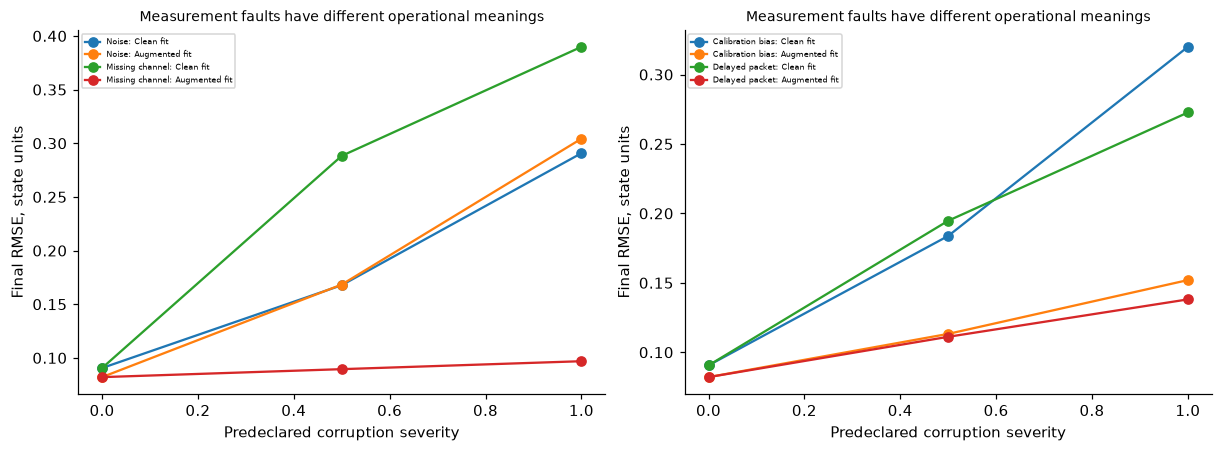

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
def cohort(n):
    latent=rng.normal(size=(n,8))
    for t in range(1,8):latent[:,t]=.8*latent[:,t-1]+.6*rng.normal(size=n)
    a=latent+rng.normal(scale=.1,size=latent.shape);b=1.5*latent+rng.normal(scale=.1,size=latent.shape);x=np.c_[a[:,-1],b[:,-1],a[:,-2],b[:,-2]];y=latent[:,-1]+rng.normal(scale=.05,size=n);return x,y,a,b
xs,ys,_,_=cohort(1200);xf,yf,af,bf=cohort(500);clean=HistGradientBoostingRegressor(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);aug=[]
for _ in range(3):
    z=xs+rng.normal(scale=.2,size=xs.shape);z[:,[0,2]]+=rng.uniform(-.3,.3,(len(z),1));drop=rng.random(len(z))<.15;z[drop,0]=np.nan;z[drop,2]=np.nan;aug.append(z)
robust=HistGradientBoostingRegressor(max_iter=100,max_depth=3,early_stopping=False,random_state=SEED).fit(np.r_[xs,*aug],np.tile(ys,4));models={'Clean fit':clean,'Augmented fit':robust};results={};challenges={}
for kind in ['Noise','Missing channel','Calibration bias','Delayed packet']:
    for level in [0.,.5,1.]:
        z=xf.copy()
        if kind=='Noise':z+=rng.normal(scale=.5*level,size=z.shape)
        if kind=='Missing channel':ids=rng.random(500)<level;z[ids,0]=np.nan;z[ids,2]=np.nan
        if kind=='Calibration bias':z[:,[0,2]]+=level
        if kind=='Delayed packet':ids=rng.random(500)<level;z[ids,0]=af[ids,-3];z[ids,2]=af[ids,-4]
        key=f'{kind} {level:g}';challenges[key]=z;results[key]={name:float(np.sqrt(np.mean((model.predict(z)-yf)**2))) for name,model in models.items()}
assert all(np.isfinite(v) for row in results.values() for v in row.values());assert np.isnan(challenges['Missing channel 1'][:,[0,2]]).all();assert np.array_equal(challenges['Delayed packet 1'][:,0],af[:,-3]);RESULTS.update(source_sequences=1200,final_sequences=500,challenge_RMSE=results,augmentation_source_rows=4800,delayed_channel_steps=2,final_outcomes_select_augmentation=False);fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,kinds in zip(axes,[['Noise','Missing channel'],['Calibration bias','Delayed packet']]):
    for kind in kinds:
        for name in models:ax.plot([0,.5,1],[results[f'{kind} {level:g}'][name] for level in [0,.5,1]],marker='o',label=f'{kind}: {name}')
    ax.set(xlabel='Predeclared corruption severity',ylabel='Final RMSE, state units',title='Measurement faults have different operational meanings');ax.legend(fontsize=5)
plt.show()


## Validate metadata before interpreting a numeric prediction
 Wrong units are deterministic transformations with known conversions, not random noise. A channel tagged in milli-units is converted by0.001 before inference; an unknown unit is rejected. For500 current packets, deliberately mark50 as unknown units,50 as two-step stale and10 as containing infinity, in disjoint blocks. A declared timestamp tolerance of one sample rejects stale packets; permitted NaNs represent explicit missing channels, while infinity is invalid. Report rejected packets and keep their service disposition separate from accepted-packet RMSE. Unit-tagged data are actually converted and checked against original features. Also show the large uncorrected unit-scale challenge and repaired known-unit prediction scores without refitting. The validator does not detect an in-range calibration bias or a hidden change in the label law.


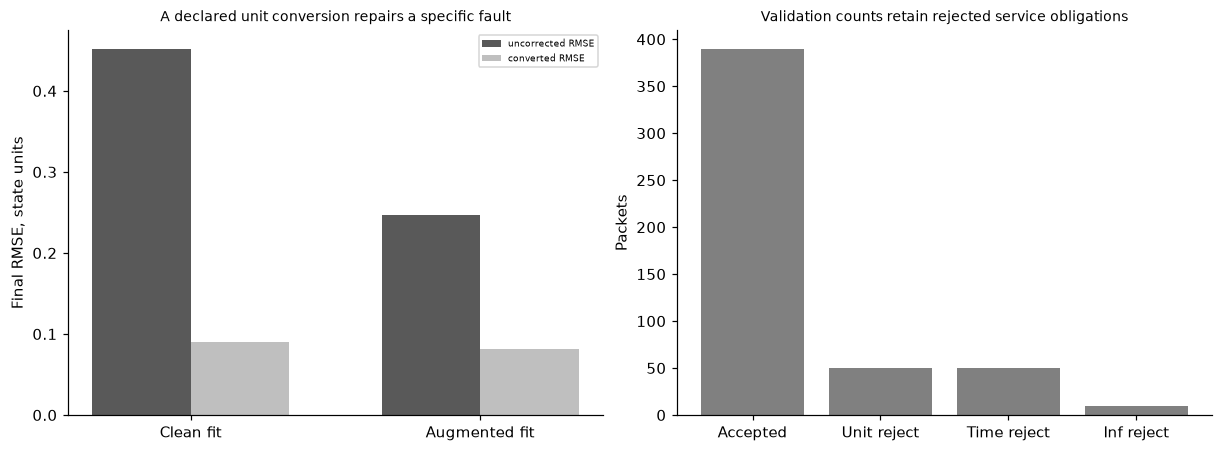

In [3]:
wrong=xf.copy();wrong[:,[0,2]]*=1000;restored=wrong.copy();restored[:,[0,2]]*=.001;assert np.allclose(restored,xf);unit_scores={name:{'uncorrected_RMSE':float(np.sqrt(np.mean((model.predict(wrong)-yf)**2))),'converted_RMSE':float(np.sqrt(np.mean((model.predict(restored)-yf)**2)))} for name,model in models.items()};unit=np.array(['known']*500);age=np.zeros(500,int);packets=xf.copy();unit[:50]='bad';age[50:100]=2;packets[100:110,0]=np.inf;accepted=(unit=='known')&(age<=1)&~np.isinf(packets).any(1);assert accepted.sum()==390;assert not accepted[:110].any();accepted_rmse={name:float(np.sqrt(np.mean((model.predict(packets[accepted])-yf[accepted])**2))) for name,model in models.items()};RESULTS.update(unit_scale_challenge=unit_scores,packet_validation={'unknown_units':50,'stale_packets':50,'infinite_values':10,'accepted':390,'rejected':110},accepted_packet_RMSE=accepted_rmse,validator_does_not_identify_hidden_conditional_shift=True);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2)
for j,field in enumerate(['uncorrected_RMSE','converted_RMSE']):axes[0].bar(xx+(j-.5)*.34,[unit_scores[k][field] for k in models],.34,label=field.replace('_',' '),color=['.35','.75'][j])
axes[0].set(xticks=xx,xticklabels=list(models),ylabel='Final RMSE, state units',title='A declared unit conversion repairs a specific fault');axes[0].legend(fontsize=6);axes[1].bar(range(4),[390,50,50,10],color='.5');axes[1].set(xticks=range(4),xticklabels=['Accepted','Unit reject','Time reject','Inf reject'],ylabel='Packets',title='Validation counts retain rejected service obligations');plt.show()


In [4]:
summary={'example_id':'code_207','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual two-channel temporal sensor regression with source-only augmentation', 'severity tests for noise missing channel calibration bias and delayed packets', 'unit timestamp and finite-value validators with explicit reject counts', 'independent clean and corrupted outcomes without challenge-selected repairs'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual two-channel temporal sensor regression with source-only augmentation", "severity tests for noise missing channel calibration bias and delayed packets", "unit timestamp and finite-value validators with explicit reject counts", "independent clean and corrupted outcomes without challenge-selected repairs"], "elapsed_seconds": 0.444, "example_id": "code_207", "hardware": "Darwin arm64 CPU", "results": {"accepted_packet_RMSE": {"Augmented fit": 0.08235533574614459, "Clean fit": 0.08866252910871224}, "augmentation_source_rows": 4800, "challenge_RMSE": {"Calibration bias 0": {"Augmented fit": 0.08208632850158316, "Clean fit": 0.09055321068090352}, "Calibration bias 0.5": {"Augmented fit": 0.11321992749271766, "Clean fit": 0.18376604907725888}, "Calibration bias 1": {"Augmented fit": 0.15196343707982685, "Clean fit": 0.319944601143324}, "Delayed packet 0": {"Augmented fit": 0.08208632850158316, "Clean fit": 0.09055321068090352}, "Delaye